# Упражнения по регуляризации и методу градиентного спуска
![UnderOverFit.png](../asets/UnderOverFit.png)


# Учебные цели

- Объяснить суть функций затрат, регуляризации, выбора признаков и гиперпараметров
- Охарактеризовать сложные алгоритмы статистической оптимизации, такие как метод градиентного спуска, и его применение в линейной регрессии
- Применять расширение Intel® для Scikit-learn*, чтобы использовать вычислительные возможности аппаратного обеспечения


## Введение

Мы начнём с краткого введения в регрессию, полиномиальные признаки и регуляризацию на примере очень простого набора разреженных данных, содержащего столбец данных `x` и соответствующие данные `y` с шумом. Файл данных называется `X_Y_Sinusoid_Data.csv`.

In [1]:
from __future__ import print_function
import os
import warnings
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import MinMaxScaler

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex не установлен, работает обычный scikit-learn')

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные.

* Также сгенерируйте примерно 100 равномерно распределенных точек данных по оси x в диапазоне от 0 до 1. Используя эти точки, вычислите данные по оси y, представляющие «истинное значение» (реальную функцию), по уравнению: $y = \sin(2\pi x)$

* Постройте график разреженных данных (`x` против `y`) и вычисленных («реальных») данных.



In [2]:
import pandas as pd
import numpy as np

filepath = os.sep.join(data_path + ['X_Y_Sinusoid_Data.csv'])
data = pd.read_csv(filepath)

X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

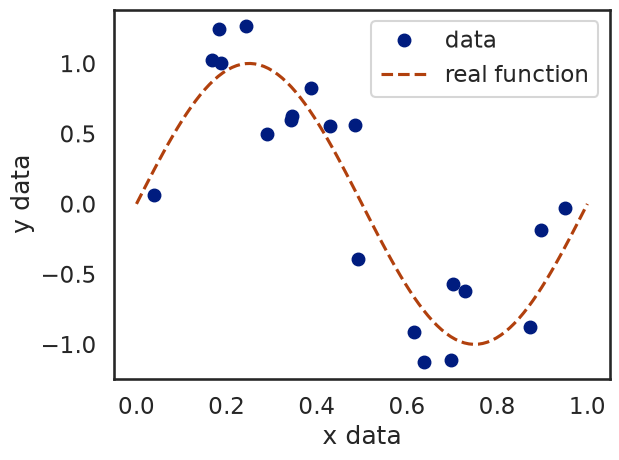

In [4]:
sns.set_style('white')
sns.set_context('talk')
sns.set_palette('dark')

# Plot of the noisy (sparse)
ax = data.set_index('x')['y'].plot(ls='', marker='o', label='data')
ax.plot(X_real, Y_real, ls='--', marker='', label='real function')

ax.legend()
ax.set(xlabel='x data', ylabel='y data');


## Вопрос 2


* Используя класс `PolynomialFeatures` из библиотеки предварительной обработки данных Scikit-learn, создайте полиномиальные признаки 20-го порядка.
* Проведите линейную регрессию по этим данным.
* Постройте график, на котором будут отображены полученные прогнозируемые значения в сравнении с расчётными данными.

Обратите внимание, что для класса `PolynomialFeatures` требуется либо датафрейм (с одним столбцом, а не серия), либо двумерный массив размером (`X`, 1), где `X` — длина.

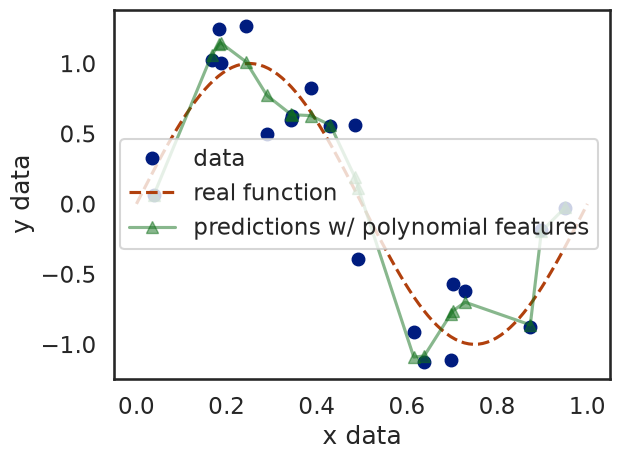

In [5]:
# Setup the polynomial features
degree = 20
pf = PolynomialFeatures(degree)
lr = LinearRegression()

# Extract the X- and Y- data from the dataframe
X_data = data[['x']].to_numpy()
Y_data = data['y'].to_numpy()

# Create the features and fit the model
X_poly = pf.fit_transform(X_data)
lr = lr.fit(X_poly, Y_data)
Y_pred = lr.predict(X_poly)

# Plot the result
plt.plot(X_data, Y_data, marker='o', ls='', label='data', alpha=1)
plt.plot(X_real, Y_real, ls='--', label='real function')
plt.plot(X_data, Y_pred, marker='^', alpha=.5, label='predictions w/ polynomial features')
plt.legend()
ax = plt.gca()
ax.set(xlabel='x data', ylabel='y data');


**Ответ.**

Точек всего 20, а у полинома 20-й степени 21 коэффициент: параметров больше, чем данных. Линейная регрессия проходит практически через каждую точку и повторяет шум, а не синусоиду. Это переобучение в чистом виде: на новых `x` между точками такая модель будет ошибаться сильно.

## Вопрос 3

* Проведите регрессионный анализ данных с полиномиальными признаками с использованием регрессии Ridge ($\alpha$ = 0,001) и регрессии Lasso ($\alpha$ = 0,0001).
* Постройте графики результатов, как это было сделано в вопросе 1.
* Также постройте график величин коэффициентов, полученных в результате этих регрессий, и сравните их с коэффициентами, полученными при линейной регрессии в предыдущем вопросе. Коэффициенты линейной регрессии, вероятно, потребуют отдельного графика (или собственной оси y) из-за их больших значений.

Что говорит вам сравнительно большая величина коэффициентов о роли регуляризации?

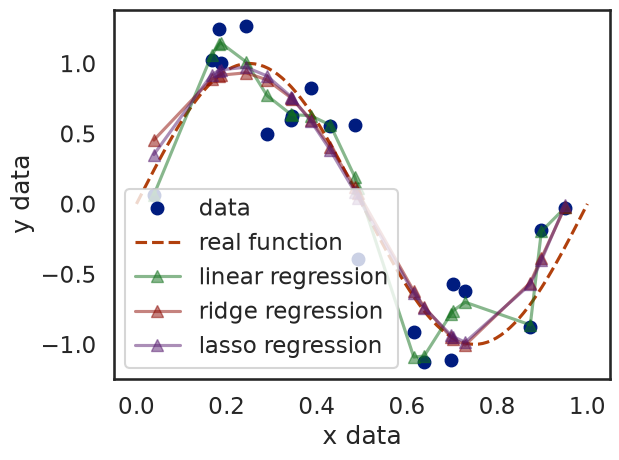

In [6]:
# Mute the sklearn warning about regularization
import warnings
warnings.filterwarnings('ignore', module='sklearn')

# The ridge regression model
rr = Ridge(alpha=0.001)
rr = rr.fit(X_poly, Y_data)
Y_pred_rr = rr.predict(X_poly)

# The lasso regression model
lassor = Lasso(alpha=0.0001)
lassor = lassor.fit(X_poly, Y_data)
Y_pred_lr = lassor.predict(X_poly)

# The plot of the predicted values
plt.plot(X_data, Y_data, marker='o', ls='', label='data')
plt.plot(X_real, Y_real, ls='--', label='real function')
plt.plot(X_data, Y_pred, label='linear regression', marker='^', alpha=.5)
plt.plot(X_data, Y_pred_rr, label='ridge regression', marker='^', alpha=.5)
plt.plot(X_data, Y_pred_lr, label='lasso regression', marker='^', alpha=.5)

plt.legend()

ax = plt.gca()
ax.set(xlabel='x data', ylabel='y data');

In [7]:
# let's look at the absolute value of coefficients for each model

coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
coefficients = coefficients.abs()   # applymap удален в pandas 3

coefficients.describe()  # Huge difference in scale between non-regularized vs regularized regression

,linear regression,ridge regression,lasso regression
count,21.000000,21.000000,21.000000
mean,10469.729021,2.169397,2.167284
std,6883.590748,2.900278,4.706731
min,0.000001,0.000000,0.000000
25%,5224.863357,0.467578,0.000000
50%,10877.407200,1.017272,0.252181
75%,15291.728297,2.883507,1.641353
max,23169.126273,12.429635,20.176708


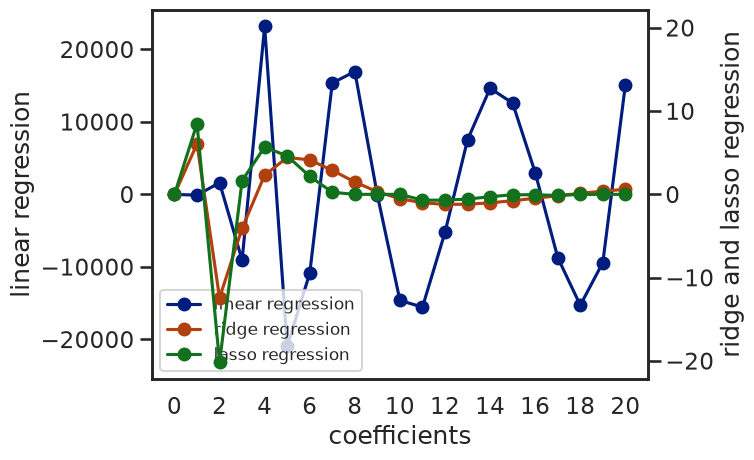

In [8]:
colors = sns.color_palette()

# Setup the dual y-axes
ax1 = plt.axes()
ax2 = ax1.twinx()

# Plot the linear regression data
ax1.plot(lr.coef_.ravel(),
         color=colors[0], marker='o', label='linear regression')

# Plot the regularization data sets
ax2.plot(rr.coef_.ravel(),
         color=colors[1], marker='o', label='ridge regression')

ax2.plot(lassor.coef_.ravel(),
         color=colors[2], marker='o', label='lasso regression')

# Customize axes scales: пределы по данным (в исходнике было +-2e14 под старую версию решателя)
lim1 = 1.1 * np.abs(lr.coef_).max()
lim2 = 1.1 * max(np.abs(rr.coef_).max(), np.abs(lassor.coef_).max())
ax1.set_ylim(-lim1, lim1)
ax2.set_ylim(-lim2, lim2)

# Combine the legends
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, fontsize=12)

ax1.set(xlabel='coefficients',ylabel='linear regression')
ax2.set(ylabel='ridge and lasso regression')

ax1.set_xticks(range(0, len(lr.coef_), 2));

**Ответ.**

Ridge и Lasso дают более гладкие кривые, ближе к истинной синусоиде, чем обычная регрессия.

По модулю коэффициенты линейной регрессии доходят до 23 тыс., а у Ridge и Lasso до 12 и 20, то есть разница в тысячу раз. Без штрафа модель подгоняет шум огромными весами разного знака, которые почти гасят друг друга. Такая модель неустойчива: небольшое изменение данных сильно меняет веса. Регуляризация штрафует размер весов и этим уменьшает дисперсию модели. У Lasso (L1) часть коэффициентов ровно равна нулю (медиана 0.25, нижний квартиль 0), то есть L1 еще и отбирает признаки, а Ridge (L2) только уменьшает все веса.

## Вопрос 4

В оставшихся вопросах мы будем работать с [набором данных](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) из прошлого занятия, который основан на данных о ценах на жилье в Эймсе, штат Айова. В наборе содержится большое количество признаков — подробнее об этих признаках см. в упражнениях третьей недели.

Для начала:

* Импортируйте данные с помощью Pandas, удалите все нулевые значения и выполните кодирование категориальных переменных методом «one-hot». Для этого можно использовать либо кодировщики признаков из Scikit-learn, либо метод `get_dummies` из Pandas.
* Разделите данные на обучающую и тестовую выборки.
* Примените логарифмическое преобразование к асимметричным признакам.
* Можно попробовать выполнить масштабирование, хотя будет интересно посмотреть, насколько хорошо работает регуляризация без масштабирования признаков.

In [9]:
filepath = os.sep.join(data_path + ['Ames_Housing_Sales.csv'])
# "None" здесь - категория "нет" (нет бассейна, забора...), а не пропуск, поэтому keep_default_na=False
data = pd.read_csv(filepath, sep=',', keep_default_na=False)
print(data.shape, 'пропусков:', data.isna().sum().sum())

(1379, 80) пропусков: 0


Создайте список категориальных данных и примените к ним кодирование «one-hot». Кодировщик «one-hot» в Pandas (`get_dummies`) хорошо подходит для данных, определённых как категориальные.

In [10]:
# Get a Pd.Series consisting of all the string categoricals
# в pandas 3 строки имеют тип str, а не object, поэтому выбираю все нечисловые столбцы
one_hot_encode_cols = data.select_dtypes(exclude='number').columns.tolist()  # list of categorical fields

# Here we see another way of one-hot-encoding:
# Encode these columns as categoricals so one hot encoding works on split data (if desired)
for col in one_hot_encode_cols:
    data[col] = pd.Categorical(data[col])

# Do the one hot encoding
# dummy-столбцы целые (uint8, как в старых pandas): иначе фильтр dtypes == float ниже захватил бы и их
data = pd.get_dummies(data, columns=one_hot_encode_cols, dtype=np.uint8)
print(data.shape)

(1379, 295)


Далее разделите данные на обучающий и тестовый наборы.

In [11]:
train, test = train_test_split(data, test_size=0.3, random_state=42)

Есть ряд столбцов с асимметричным распределением — к ним можно применить логарифмическое преобразование. Обратите внимание, что в их число входит и `SalePrice` — наш предиктор. Однако давайте оставим его без изменений.

In [12]:
# Create a list of float colums to check for skewing
mask = data.dtypes == float
float_cols = data.columns[mask]

In [13]:
skew_limit = 0.75
skew_vals = train[float_cols].skew()

skew_cols = (skew_vals
             .sort_values(ascending=False)
             .to_frame()
             .rename(columns={0:'Skew'})
             .query('abs(Skew) > {0}'.format(skew_limit)))

skew_cols

,Skew
MiscVal,26.915364
PoolArea,15.777668
LotArea,11.501694
LowQualFinSF,11.210638
3SsnPorch,10.150612
ScreenPorch,4.599803
BsmtFinSF2,4.466378
EnclosedPorch,3.218303
LotFrontage,3.138032
MasVnrArea,2.492814


Преобразуйте все столбцы, в которых коэффициент асимметрии превышает 0,75, за исключением столбца «SalePrice».

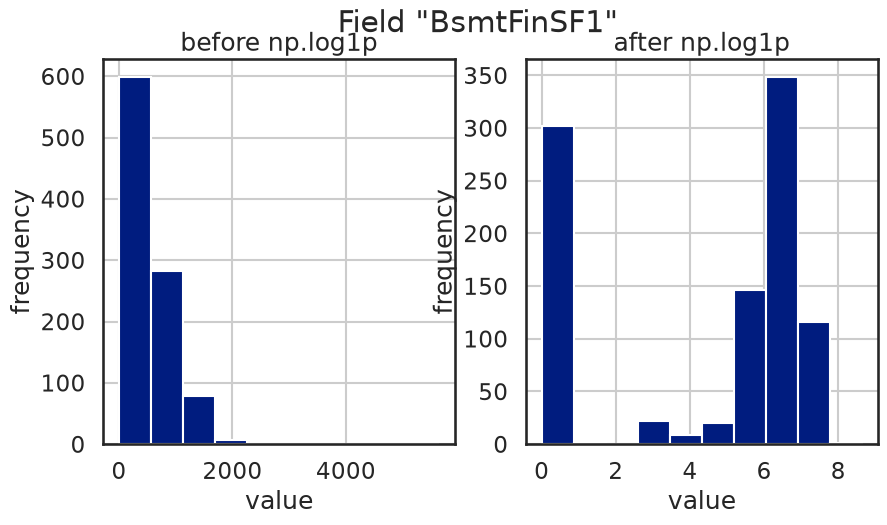

In [14]:
# OPTIONAL: Let's look at what happens to one of these features, when we apply np.log1p visually.

field = "BsmtFinSF1"
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 5))
train[field].hist(ax=ax_before)
train[field].apply(np.log1p).hist(ax=ax_after)
ax_before.set(title='before np.log1p', ylabel='frequency', xlabel='value')
ax_after.set(title='after np.log1p', ylabel='frequency', xlabel='value')
fig.suptitle('Field "{}"'.format(field));
# a little bit better

In [15]:
# Mute the setting wtih a copy warnings
pd.options.mode.chained_assignment = None

for col in skew_cols.index.tolist():
    if col == "SalePrice":
        continue
    train[col] = np.log1p(train[col])
    test[col]  = test[col].apply(np.log1p)  # same thing

Выделить признаки из набора предикторов.

In [16]:
feature_cols = [x for x in train.columns if x != 'SalePrice']
X_train = train[feature_cols].to_numpy()
y_train = train['SalePrice'].to_numpy()

X_test  = test[feature_cols].to_numpy()
y_test  = test['SalePrice'].to_numpy()

## Вопрос 5

* Напишите функцию **`rmse`**, которая принимает в качестве аргументов значения истинных и прогнозируемых значений и возвращает среднеквадратичную ошибку. Используйте функцию `mean_squared_error` из библиотеки sklearn.


In [17]:
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Построить базовую модель линейной регрессии
* Вывести среднеквадратичную ошибку для этой модели
* Построить график сопоставления прогнозируемой и фактической цены продажи на основе модели.

In [18]:
linearRegression = LinearRegression().fit(X_train, y_train)

linearRegression_rmse = rmse(y_test, linearRegression.predict(X_test))

print(linearRegression_rmse)
print(f'для сравнения: цена на test в среднем {y_test.mean():,.0f} $, стандартное отклонение {y_test.std():,.0f} $ '
      f'(это RMSE константы, равной среднему)')

306369.68342317565
для сравнения: цена на test в среднем 183,217 $, стандартное отклонение 77,698 $ (это RMSE константы, равной среднему)


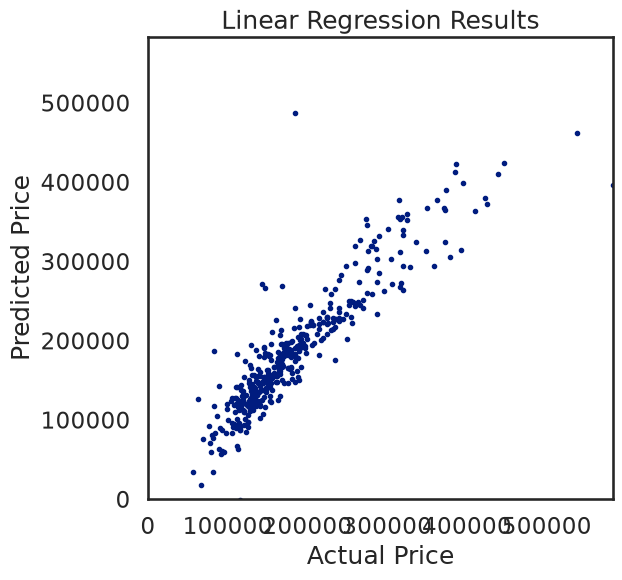

In [19]:
f = plt.figure(figsize=(6,6))
ax = plt.axes()

ax.plot(y_test, linearRegression.predict(X_test),
         marker='o', ls='', ms=3.0)

lim = (0, y_test.max())

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       xlim=lim,
       ylim=lim,
       title='Linear Regression Results');

**Ответ.**

RMSE обычной линейной регрессии 306 370 $, а цена на test в среднем 183 тыс. $ при стандартном отклонении 78 тыс. $. Константа, равная средней цене, ошибалась бы на 78 тыс., то есть модель на test в 4 раза хуже константы. Это та же проблема, что в лабе 3: One-Hot здесь создает n столбцов на признак (dummy trap), признаков 294 при 965 домах в train, много редких категорий. Матрица признаков вырождена, и на домах test с редкими категориями прогноз улетает (точки далеко от диагонали на графике).

## Вопрос 6

В регрессии Риджа используется L2-нормализация для уменьшения величины коэффициентов. Это может быть полезно в ситуациях с высокой дисперсией. Каждая из функций регуляризации в Scikit-learn содержит версии со встроенной перекрестной валидацией.

* Постройте обычную (без перекрестной валидации) модель Риджа для диапазона значений $\alpha$ и постройте график среднеквадратичной ошибки (RMSE) с использованием созданной вами выше функции ошибки с перекрестной валидацией.
* Используйте $$[0,005; 0,05; 0,1; 0,3; 1; 3; 5; 10; 15; 30; 80]$$ в качестве диапазона значений $\alpha$.
* Затем повторите подбор моделей Риджа, используя диапазон значений $\alpha$ из предыдущего раздела. Сравните результаты.

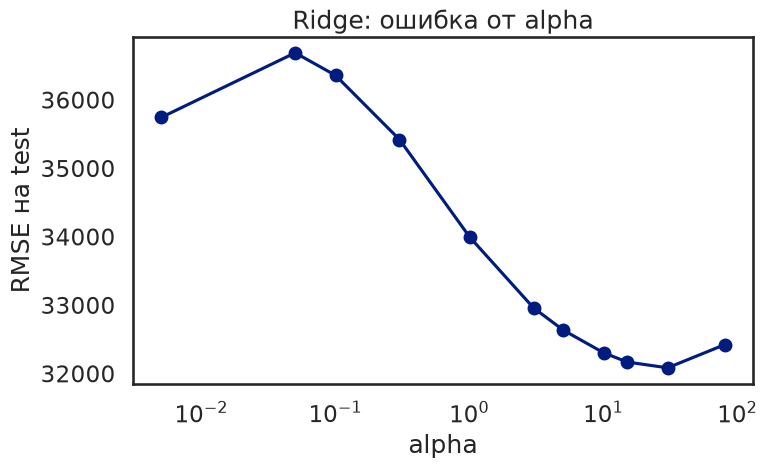

лучшее alpha на test: 30.0  RMSE: 32085


In [20]:
# обычный Ridge (без встроенной кросс-валидации) для каждого alpha: ошибка на test
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

ridge_rmses = pd.Series({alpha: rmse(y_test, Ridge(alpha=alpha).fit(X_train, y_train).predict(X_test))
                         for alpha in alphas}, name='RMSE')

ax = ridge_rmses.plot(marker='o', logx=True, figsize=(8, 4.5))
ax.set(xlabel='alpha', ylabel='RMSE на test', title='Ridge: ошибка от alpha')
plt.show()
print('лучшее alpha на test:', ridge_rmses.idxmin(), ' RMSE:', round(ridge_rmses.min()))

Теперь рассмотрим метод `RidgeCV`. К сожалению, получить значения альфа для моделей, которые не были выбраны, не представляется возможным. Полученные значения ошибок и значения $\alpha$ очень похожи на те, что были получены выше.

In [21]:
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

ridgeCV = RidgeCV(alphas=alphas,
                  cv=4).fit(X_train, y_train)

ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print(ridgeCV.alpha_, ridgeCV_rmse)

15.0 32169.176205672422


**Ответ.**

У обычного Ridge, если перебирать alpha по test, лучшее alpha = 30 и RMSE 32 085 $. `RidgeCV` выбирает alpha по кросс-валидации на train, не глядя на test, и выбрал 15 (RMSE 32 169 $). Результаты почти одинаковы, но правильный способ - `RidgeCV`: подбор по test подгоняет гиперпараметр под test, и оценка ошибки становится слишком оптимистичной. Регуляризация уменьшила ошибку почти в 10 раз по сравнению с обычной регрессией (306 тыс. -> 32 тыс.).

## Вопрос 7


Подобно функции `RidgeCV`, существует также функция `LassoCV`, которая использует функцию регуляризации L1 и перекрестную валидацию. Регуляризация L1 выборочно уменьшает некоторые коэффициенты, что фактически приводит к удалению признаков.

Функция `LassoCV` не позволяет задавать функцию оценки. Однако для оценки ошибки конечной модели можно использовать созданную выше пользовательскую функцию ошибки (`rmse`).

Аналогично существует также функция ElasticNet с перекрестной валидацией — `ElasticNetCV`, представляющая собой комбинацию регуляризаций L2 и L1.

* Постройте модель Lasso с использованием перекрестной валидации и определите оптимальное значение $\alpha$ и RMSE с помощью созданной выше функции. Обратите внимание, что величина $\alpha$ может отличаться от значения для модели Ridge.
* Повторите эту процедуру для модели ElasticNet.
* Сравните результаты с помощью таблицы и/или графика.

Используйте следующие значения $\alpha$:
`[1e-5, 5e-5, 0.0001, 0.0005]`

In [22]:
alphas2 = np.array([1e-5, 5e-5, 0.0001, 0.0005])

lassoCV = LassoCV(alphas=alphas2,
                  max_iter=50_000,
                  cv=3).fit(X_train, y_train)

lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print(lassoCV.alpha_, lassoCV_rmse)  # Lasso is slower

0.0005 39257.39399154079


Мы можем определить, сколько из этих характеристик остаются неравными нулю.

In [23]:
print('Of {} coefficients, {} are non-zero with Lasso.'.format(len(lassoCV.coef_),
                                                               len(lassoCV.coef_.nonzero()[0])))

Of 294 coefficients, 273 are non-zero with Lasso.


Теперь попробуйте использовать метод «Elastic Net» с теми же значениями альфа, что и в методе «Lasso», и значениями l1_ratios в диапазоне от 0,1 до 0,9

In [24]:
l1_ratios = np.linspace(0.1, 0.9, 9)

elasticNetCV = ElasticNetCV(alphas=alphas2,
                            l1_ratio=l1_ratios,
                            max_iter=10_000).fit(X_train, y_train)
elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print(elasticNetCV.alpha_, elasticNetCV.l1_ratio_, elasticNetCV_rmse)

0.0005 0.1 35001.23429607445


Сравнить результаты расчета среднеквадратичной ошибки (RMSE) для всех моделей проще всего в таблице.

In [25]:
rmse_vals = [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]

labels = ['Linear', 'Ridge', 'Lasso', 'ElasticNet']

rmse_df = pd.Series(rmse_vals, index=labels).to_frame()
rmse_df.rename(columns={0: 'RMSE'}, inplace=1)
rmse_df

,RMSE
Linear,306369.683423
Ridge,32169.176206
Lasso,39257.393992
ElasticNet,35001.234296


Мы также можем построить график, на котором будут отображены фактические и прогнозируемые цены на жилье, как и ранее.

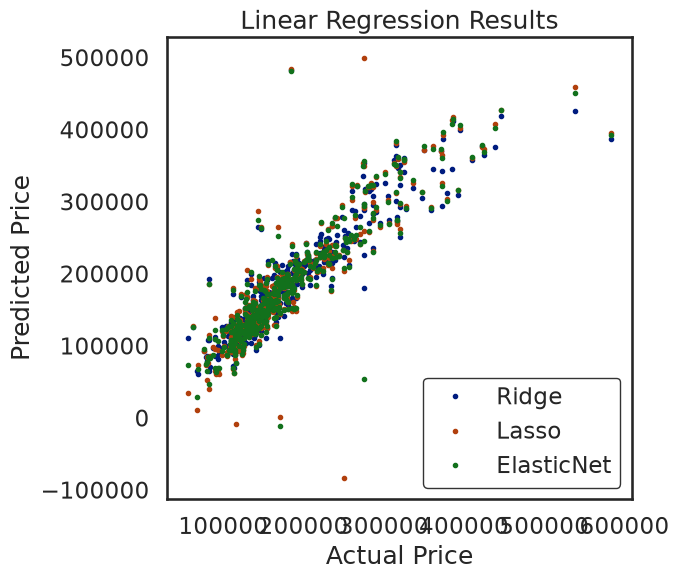

In [26]:
f = plt.figure(figsize=(6,6))
ax = plt.axes()

labels = ['Ridge', 'Lasso', 'ElasticNet']

models = [ridgeCV, lassoCV, elasticNetCV]

for mod, lab in zip(models, labels):
    ax.plot(y_test, mod.predict(X_test),
             marker='o', ls='', ms=3.0, label=lab)


leg = plt.legend(frameon=True)
leg.get_frame().set_edgecolor('black')
leg.get_frame().set_linewidth(1.0)

ax.set(xlabel='Actual Price',
       ylabel='Predicted Price',
       title='Linear Regression Results');

**Ответ.**

| модель | alpha | RMSE test, $ |
|---|---|---|
| Linear | - | 306 370 |
| Ridge (RidgeCV) | 15 | 32 169 |
| Lasso (LassoCV) | 0.0005 | 39 257 |
| ElasticNet (l1_ratio = 0.1) | 0.0005 | 35 001 |

Lasso и ElasticNet выбрали **самое большое** alpha из сетки (0.0005), значит, оптимум за ее границей, и сетку стоило бы расширить. При цене в долларах (порядка 10^5) штраф alpha = 0.0005 почти ничего не делает: у Lasso ненулевые 273 коэффициента из 294. ElasticNet выбрал l1_ratio = 0.1, то есть почти Ridge. В этой постановке лучший результат у Ridge.

## Вопрос 8

В этом упражнении рассмотрим метод стохастического градиентного спуска (SGD).
Напомним, что линейные модели в целом чувствительны к масштабированию.
Однако метод SGD *очень* чувствителен к масштабированию.
Кроме того, высокое значение скорости обучения может привести к расхождению алгоритма, тогда как слишком низкое значение может привести к слишком длительному процессу сходимости.

* Постройте модель со стохастическим градиентным спуском без штрафа регуляризации (соответствующий параметр — `penalty`).
* Теперь постройте модели со стохастическим градиентным спуском с каждым из трёх штрафов (L2, L1, Elastic Net), используя значения параметров, определённые выше с помощью перекрёстной валидации.
* Не масштабируйте данные перед построением модели.
* Сравните результаты с теми, которые были получены без использования метода стохастического градиентного спуска.

In [27]:
# В исходной версии параметры перепутаны: у 'Lasso' стоял штраф l2, а у 'Ridge' вместо alpha_ подставлялась
# RMSE модели. penalty='none' в новых версиях sklearn - это None.
model_parameters_dict = {
    'Linear': {'penalty': None},
    'Ridge': {'penalty': 'l2',
              'alpha': ridgeCV.alpha_},
    'Lasso': {'penalty': 'l1',
              'alpha': lassoCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet',
                   'alpha': elasticNetCV.alpha_,
                   'l1_ratio': elasticNetCV.l1_ratio_}
}


def sgd_rmse(parameters, Xtr, Xte, **extra):
    """RMSE модели SGD на test; если SGD разошелся (переполнение), возвращает inf."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            SGD = SGDRegressor(random_state=42, **extra, **parameters).fit(Xtr, y_train)
            pred = SGD.predict(Xte)
            return rmse(y_test, pred) if np.isfinite(pred).all() and np.abs(pred).max() < 1e100 else np.inf
    except ValueError as e:      # "Floating-point under-/overflow occurred at epoch ..."
        return np.inf


new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    new_rmses[modellabel] = sgd_rmse(parameters, X_train, X_test)

rmse_df['RMSE-SGD'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD
Linear,306369.683423,2.971357e+14
Ridge,32169.176206,2.845393e+15
Lasso,39257.393992,2.978886e+14
ElasticNet,35001.234296,7.465196e+14


Обратите внимание, насколько велики значения ошибок! Алгоритм расходится. Это может быть связано со слишком высоким коэффициентом масштабирования и/или слишком высокой скоростью обучения. Давайте скорректируем скорость обучения и посмотрим, что произойдет.

In [28]:
new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    new_rmses[modellabel] = sgd_rmse(parameters, X_train, X_test, eta0=1e-7)

rmse_df['RMSE-SGD-learningrate'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-learningrate
Linear,306369.683423,2.971357e+14,74723.233315
Ridge,32169.176206,2.845393e+15,74727.722345
Lasso,39257.393992,2.978886e+14,74723.233320
ElasticNet,35001.234296,7.465196e+14,74723.233450


Now let's scale our training data and try again.

* Fit a `MinMaxScaler` to `X_train` create a variable `X_train_scaled`.
* Using the scaler, transform `X_test` and create a variable `X_test_scaled`.
* Apply the same versions of SGD to them and compare the results. Don't pass in a eta0 this time.

In [29]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    new_rmses[modellabel] = sgd_rmse(parameters, X_train_scaled, X_test_scaled)

rmse_df['RMSE-SGD-scaled'] = pd.Series(new_rmses)
rmse_df

,RMSE,RMSE-SGD,RMSE-SGD-learningrate,RMSE-SGD-scaled
Linear,306369.683423,2.971357e+14,74723.233315,33250.211138
Ridge,32169.176206,2.845393e+15,74727.722345,72313.907660
Lasso,39257.393992,2.978886e+14,74723.233320,33250.208481
ElasticNet,35001.234296,7.465196e+14,74723.233450,33221.583545


In [30]:
# Почему Ridge через SGD так плох: alpha в Ridge стоит при сумме ошибок, а в SGDRegressor - при средней.
# Эквивалентный штраф для SGD = alpha_Ridge / n_train.
n_train = X_train_scaled.shape[0]
fixed = {'penalty': 'l2', 'alpha': ridgeCV.alpha_ / n_train}
print(f'Ridge alpha = {ridgeCV.alpha_}, для SGD: {ridgeCV.alpha_} / {n_train} = {fixed["alpha"]:.4f}')
print('RMSE SGD (Ridge) с пересчитанным alpha:', round(sgd_rmse(fixed, X_train_scaled, X_test_scaled)))

Ridge alpha = 15.0, для SGD: 15.0 / 965 = 0.0155
RMSE SGD (Ridge) с пересчитанным alpha: 32766


**Ответ.**

- **SGD без масштабирования** разошелся: RMSE около 10^14-10^15 $. Признаки в очень разных масштабах (годы около 2000 рядом с dummy 0/1), и шаг по умолчанию слишком велик для признаков с большими значениями.
- **С `eta0 = 1e-7`** SGD не расходится, но почти ничего не выучивает: у всех четырех моделей одна и та же ошибка около 74.7 тыс. $, это уровень модели, близкой к константе (std цены на test 78 тыс.).
- **С `MinMaxScaler`** все признаки в [0, 1], и SGD работает: Linear 33 250 $, Lasso 33 250 $, ElasticNet 33 222 $, на уровне точных решателей. Без регуляризации SGD тут даже лучше обычной `LinearRegression` (306 тыс.): SGD стартует с нулевых весов и останавливается рано, это работает как неявная регуляризация, и вырожденность матрицы ему не мешает.
- **Ridge через SGD дал 72 тыс. $.** Дело не в SGD: alpha в `Ridge` стоит при сумме квадратов ошибок, а в `SGDRegressor` - при средней ошибке. Поэтому alpha = 15 в SGD - штраф в n = 965 раз сильнее. С alpha = 15 / 965 = 0.0155 SGD дает 32 766 $, как точный Ridge. У Lasso и ElasticNet в sklearn ошибка тоже усредняется по объектам, поэтому их alpha можно переносить в SGD как есть.

Вывод: для SGD масштабирование признаков обязательно, а гиперпараметры нужно переносить с учетом того, как каждая модель записывает свою функцию потерь.